# 06 : Explainability : LIME token attributions for M0 and M1

Purpose: turn each model's verdict into evidence an analyst can read. For
the same emails, explain M0 (TF-IDF + Logistic Regression) and M1
(Text-CNN) with LIME, compare what each one keys on, and measure how far
an explanation moves when only LIME's random seed changes. This is build
step 12 and the XAI half of the extra features. Author: Colile Sibanda.

**Sign convention, stated once and followed everywhere** (see
`src/phishlens/explain/README.md`): a **positive** weight pushes the
prediction **towards phishing** (label 1); a negative weight pushes it
towards legitimate (label 0).

**What is explained.** LIME is handed the *normalised*
text, not the raw email, and the project tokeniser is handed to LIME as its
`split_expression`. The normalised text is what the model actually sees:
it has been lowercased and has had URLs, email addresses and number runs
replaced by `<url>`, `<email>` and `<num>`. Attributing a weight to a raw
URL span would claim an attribution the model never made : it saw `<url>`,
one token, not a domain. Every character offset below therefore indexes
into the normalised string, which each `Explanation` carries with it.

**An explanation is local.** These weights describe *this* prediction in
the neighbourhood of *this* email, fitted by a surrogate linear model on
perturbations of it. They are not a statement about the model in general
(Ribeiro et al., 2016). The report and the desktop app both say so.

**This notebook does not touch `data/processed/test.csv`.** Per
`notebooks/README.md` the test split is loaded in `04_evaluate.ipynb`
only, exactly once. Every email explained here comes from the validation
split, including the false-positive review : validation false positives
make the same qualitative point without spending the test set a second
time.

In [1]:
import inspect
import os
import subprocess
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

# Notebooks run with the kernel's cwd set to notebooks/; load_config() reads
# a path relative to the repo root, so move up to it first.
_repo_root = Path.cwd()
while not (_repo_root / "pyproject.toml").exists():
    _repo_root = _repo_root.parent
os.chdir(_repo_root)

from phishlens.config.loader import load_config
from phishlens.config.seeding import set_global_seed
from phishlens.evaluation.metrics import compute_metrics, select_threshold
from phishlens.explain.attributions import align_to_tokens, top_tokens
from phishlens.explain.lime_explainer import explain_text
from phishlens.explain.predict_fn import (
    make_baseline_predict_fn,
    make_text_cnn_predict_fn,
)
from phishlens.explain.stability import stability_report
from phishlens.features.normalise import normalise_text
from phishlens.features.vocabulary import Vocabulary
from phishlens.models.baseline import build_baseline
from phishlens.models.text_cnn import build_text_cnn
from phishlens.training.checkpoint import restore_best

config = load_config()
set_global_seed(config.seed)
run_commit = subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()

print(f"Config seed: {config.seed}")
print(f"Commit hash: {run_commit}")
print(f"Run date: {datetime.now().isoformat(timespec='seconds')}")
print(f"Explain method: {config.explain.method}")
print(f"Tokens per explanation: {config.explain.num_features}")
print(f"LIME perturbations per explanation: {config.explain.num_samples}")
print(f"Stability seeds: {list(config.explain.stability_seeds)}")

Config seed: 42
Commit hash: 099dd243596fa98094809253892ed7a049b7b04a
Run date: 2026-10-18T00:35:06
Explain method: lime
Tokens per explanation: 15
LIME perturbations per explanation: 1000
Stability seeds: [42, 1337]


## The explanation path, printed in full

Per `notebooks/README.md`, the logic a reader needs to read is printed
into the notebook with `inspect.getsource` rather than only imported. The
two functions below are the whole of the build correctness claim:
`align_to_tokens` is the off-by-one guard, and `explain_text` is the LIME
wrapper that decides what string is explained.

Read `align_to_tokens` for the direction of the loop. It walks the
**text's own tokens** and looks each one up in LIME's weight map, rather
than walking the weight map and searching the text. That direction is what
makes a misalignment impossible: the output is driven by the input, so a
token can never be reported at another token's offsets, and a weight for a
token absent from the text is simply never emitted.

In [2]:
print(inspect.getsource(align_to_tokens))

def align_to_tokens(text: str, weights: dict[str, float]) -> list[TokenWeight]:
    """Attach LIME's per-word weights to every token occurrence in `text`.

    This is the function the build is marked correctness-critical for. It
    walks the text's own tokens in order and looks each one up in the weight
    map, rather than walking the weight map and searching the text. That
    direction is deliberate and is what prevents the off-by-one: the output is
    driven by the input's tokens, so a token can never be reported at another
    token's offsets, and an extra entry in `weights` that does not occur in
    the text is simply never emitted.

    Offsets are found with a forward-only scan (`str.find` from a cursor), so
    repeated tokens resolve to successive occurrences instead of all pointing
    at the first one.

    `text` must be the same string that was handed to LIME : the normalised
    text, not the raw email. Passing raw text here
    would produce offsets into a string th

In [3]:
print(inspect.getsource(explain_text))

def explain_text(
    text: str,
    predict_fn: ProbabilityFn,
    config: Config,
    seed: int | None = None,
) -> Explanation:
    """Explain one email's phishing prediction as signed per-token weights.

    LIME is handed the *normalised* text, not the raw email, and the project
    tokeniser is handed to it as `split_expression`. Both
    halves of that matter:

    - Normalised, because LIME's `_segment_with_tokens` requires every token
      the tokeniser returns to appear literally in the string it was given.
      `normalise_text` lowercases and substitutes `<url>`/`<num>`, so tokens
      drawn from normalised text do not occur in the raw text and LIME raises
      "Tokenization produced tokens that do not belong in string!". More
      importantly, the normalised text is what the model actually sees, so it
      is the only string an attribution can honestly point at.
    - The project tokeniser, so the units LIME perturbs are exactly the units
      the encoder turns into 

## Load the splits and both models

M1 is the checkpoint with the best epoch's weights
restored : the same weights `04_evaluate.ipynb` reported test numbers for.
M0 is refit here on the training split, exactly as `04_evaluate.ipynb`
fits it, because the baseline pipeline is not persisted to disk.

Both are wrapped by `explain/predict_fn.py` into the *same* two-column
probability contract LIME expects. That wrapper is the same code path the
`/explain` endpoint will call : `explain/README.md`
requires that the function handed to LIME is the deployed path, not a
reimplementation of it, since an explanation of a different pipeline is
not an explanation.

In [4]:
processed_dir = Path(config.paths.processed)
label_column = config.data.label_column

train_df = pd.read_csv(processed_dir / "train.csv")
validation_df = pd.read_csv(processed_dir / "validation.csv")

print(f"Train rows: {len(train_df)}")
print(f"Validation rows: {len(validation_df)}")
print(f"Validation positive rate: {validation_df[label_column].mean():.4f}")

Train rows: 57736
Validation rows: 12372
Validation positive rate: 0.5200


In [5]:
m0_pipeline = build_baseline(config)
m0_pipeline.fit(train_df["text"].tolist(), train_df[label_column].to_numpy())
m0_predict = make_baseline_predict_fn(m0_pipeline)

print(f"M0 fitted on {len(train_df)} training rows")
print(f"M0 classes: {list(m0_pipeline.classes_)}")

M0 fitted on 57736 training rows
M0 classes: [np.int64(0), np.int64(1)]


In [6]:
vocabulary = Vocabulary.load(Path(config.paths.models) / "vocabulary.json")
m1_model = build_text_cnn(vocabulary.size(), config)
restore_best(m1_model, Path(config.serving.model_file))
m1_predict = make_text_cnn_predict_fn(m1_model, vocabulary, config)

print(f"Vocabulary size: {vocabulary.size()}")
print(f"M1 checkpoint: {config.serving.model_file}")
print(f"M1 training mode (must be False): {m1_model.training}")

Vocabulary size: 40000
M1 checkpoint: artifacts/models/text_cnn_best.pt
M1 training mode (must be False): False


## Choose the emails to explain

Four validation emails, chosen to cover the cases an analyst actually
meets rather than only the easy one:

1. a confidently-flagged phishing email,
2. a confidently-passed legitimate email,
3. a **false positive** : legitimate, but M1 flagged it (the review
   `notebooks/README.md` asks this notebook for),
4. a **borderline** email, whose probability sits nearest the decision
   threshold and where an explanation is worth the most.

Selection uses M1's validation probabilities and the threshold selected on
validation, the same the design discipline as `04_evaluate.ipynb`. Nothing here
touches the test split.

In [7]:
validation_texts = validation_df["text"].tolist()
validation_labels = validation_df[label_column].to_numpy()

m1_validation_probabilities = m1_predict(validation_texts)[:, 1]
selected_threshold = select_threshold(
    validation_labels, m1_validation_probabilities, objective="macro_f1"
)

validation_scored = validation_df.assign(probability=m1_validation_probabilities)
validation_scored["predicted"] = (
    validation_scored["probability"] >= selected_threshold
).astype(int)

print(f"M1 selected threshold (validation): {selected_threshold:.4f}")
print(
    "M1 validation metrics: "
    f"{compute_metrics(validation_labels, m1_validation_probabilities, selected_threshold).as_dict()}"
)

M1 selected threshold (validation): 0.5698
M1 validation metrics: {'accuracy': 0.9862592951826705, 'precision': 0.9837787733662907, 'recall': 0.9898958495258822, 'f1': 0.9868278320161166, 'macro_f1': 0.9862336490710757, 'auc_roc': 0.9988271610641659, 'average_precision': 0.9988166187400724}


In [8]:
confident_phish = validation_scored[
    (validation_scored[label_column] == 1) & (validation_scored["predicted"] == 1)
].nlargest(1, "probability")

confident_legitimate = validation_scored[
    (validation_scored[label_column] == 0) & (validation_scored["predicted"] == 0)
].nsmallest(1, "probability")

false_positives = validation_scored[
    (validation_scored[label_column] == 0) & (validation_scored["predicted"] == 1)
].nlargest(1, "probability")

borderline = validation_scored.assign(
    distance=(validation_scored["probability"] - selected_threshold).abs()
).nsmallest(1, "distance")

cases: list[tuple[str, pd.Series]] = []
for name, frame in [
    ("Confident phishing (true positive)", confident_phish),
    ("Confident legitimate (true negative)", confident_legitimate),
    ("False positive : legitimate, flagged", false_positives),
    ("Borderline : nearest the threshold", borderline),
]:
    if frame.empty:
        print(f"No validation example available for: {name}")
        continue
    cases.append((name, frame.iloc[0]))

print(f"\nFalse positives in validation: {len(validation_scored[(validation_scored[label_column] == 0) & (validation_scored['predicted'] == 1)])}")
print(f"Cases selected for explanation: {len(cases)}")
for name, row in cases:
    print(f"  {name}: corpus={row['corpus']}, label={row[label_column]}, P(phishing)={row['probability']:.4f}")


False positives in validation: 105
Cases selected for explanation: 4
  Confident phishing (true positive): corpus=Nigerian_Fraud, label=1, P(phishing)=1.0000
  Confident legitimate (true negative): corpus=Enron, label=0, P(phishing)=0.0000
  False positive : legitimate, flagged: corpus=Ling, label=0, P(phishing)=1.0000
  Borderline : nearest the threshold: corpus=CEAS_08, label=1, P(phishing)=0.5698


## A readable rendering of one explanation

`render_explanation` is presentation only : it prints the top tokens with
their signed weights and marks the direction each one pushed. The
attribution itself is computed in `src/phishlens/explain/`, so this cell
adds no logic the tests do not already cover.

In [9]:
def render_explanation(title: str, explanation, top_n: int = 10) -> None:
    """Print one explanation's top tokens with signed weights and offsets.

    Inputs: title : heading for this block; explanation : an Explanation from
    explain_text; top_n : how many tokens to show.
    Output: none; prints to the notebook.
    """
    print(f"{title}")
    print(f"P(phishing): {explanation.probability:.4f}")
    print(f"Seed: {explanation.seed}")
    print(f"Tokens in email: {len(explanation.tokens)}")
    print(f"{'token':>18}  {'weight':>9}  direction   offsets")
    for entry in explanation.top[:top_n]:
        direction = "phishing" if entry.pushes_towards_phishing() else "legitimate"
        print(
            f"{entry.token!r:>18}  {entry.weight:+9.4f}  {direction:>10}   "
            f"[{entry.start}:{entry.end}]"
        )


def verify_offsets(explanation) -> bool:
    """Re-check in the notebook that every offset slices back to its token.

    The same invariant `tests/critical/test_attribution_alignment.py` proves,
    asserted again here on real emails so a reader sees it hold on the actual
    data rather than only in a test file.

    Inputs: explanation : an Explanation from explain_text.
    Output: True if every offset pair reproduces its own token.
    """
    return all(
        explanation.text[entry.start : entry.end] == entry.token
        for entry in explanation.tokens
    )

## M0 against M1 on the same emails

LIME is model-agnostic, which is exactly why it was chosen as the primary
method: the two models are explained through
the same interface, so the token lists below are directly comparable.

M0 is a linear model over TF-IDF n-grams, so its explanation should track
its own coefficients closely. M1 pools over convolutional phrase
detectors, so it has the *option* of keying on multi-token lures. Where
the two disagree is the interesting part for report section 3.3.

In [10]:
explanations: dict[str, dict[str, object]] = {}

for name, row in cases:
    email_text = row["text"]
    m0_explanation = explain_text(email_text, m0_predict, config)
    m1_explanation = explain_text(email_text, m1_predict, config)
    explanations[name] = {
        "row": row,
        "m0": m0_explanation,
        "m1": m1_explanation,
    }

    print("=" * 78)
    print(f"{name}")
    print(f"Corpus: {row['corpus']}   True label: {row[label_column]}")
    print("=" * 78)
    render_explanation("--- M0 TF-IDF + Logistic Regression ---", m0_explanation)
    print()
    render_explanation("--- M1 Text-CNN ---", m1_explanation)
    print()
    print(f"M0 offsets verified: {verify_offsets(m0_explanation)}")
    print(f"M1 offsets verified: {verify_offsets(m1_explanation)}")
    print()

Confident phishing (true positive)
Corpus: Nigerian_Fraud   True label: 1
--- M0 TF-IDF + Logistic Regression ---
P(phishing): 0.9787
Seed: 42
Tokens in email: 1030
             token     weight  direction   offsets
           'money'    +0.1335    phishing   [257:262]
               'i'    -0.1232  legitimate   [163:164]
             'you'    +0.1143    phishing   [94:97]
            'bank'    +0.0816    phishing   [303:307]
             'the'    -0.0761  legitimate   [253:256]
            'your'    +0.0751    phishing   [79:83]
         'account'    +0.0700    phishing   [308:315]
            'that'    -0.0532  legitimate   [59:63]
              'my'    +0.0475    phishing   [48:50]
             'god'    +0.0407    phishing   [109:112]

--- M1 Text-CNN ---
P(phishing): 1.0000
Seed: 42
Tokens in email: 1030
             token     weight  direction   offsets
        'thousand'    +0.0064    phishing   [583:591]
            'your'    +0.0059    phishing   [79:83]
           "god's"    +

Confident legitimate (true negative)
Corpus: Enron   True label: 0
--- M0 TF-IDF + Logistic Regression ---
P(phishing): 0.0001
Seed: 42
Tokens in email: 212
             token     weight  direction   offsets
           'enron'    -0.0149  legitimate   [239:244]
           '<num>'    -0.0086  legitimate   [65:70]
         'meeting'    -0.0059  legitimate   [5:12]
           'vince'    -0.0058  legitimate   [152:157]
            'mark'    -0.0047  legitimate   [285:289]
          'thanks'    -0.0046  legitimate   [685:691]
           'would'    -0.0045  legitimate   [125:130]
             'you'    +0.0042    phishing   [665:668]
             'hou'    -0.0041  legitimate   [382:385]
              'pm'    -0.0041  legitimate   [209:211]

--- M1 Text-CNN ---
P(phishing): 0.0000
Seed: 42
Tokens in email: 212
             token     weight  direction   offsets
        'crenshaw'    -0.0007  legitimate   [408:416]
           '<num>'    -0.0007  legitimate   [65:70]
            'mark'    -0.0007

False positive : legitimate, flagged
Corpus: Ling   True label: 0
--- M0 TF-IDF + Logistic Regression ---
P(phishing): 0.8661
Seed: 42
Tokens in email: 21
             token     weight  direction   offsets
        'software'    +0.1196    phishing   [7:15]
             'you'    +0.0745    phishing   [55:58]
             'sir'    +0.0705    phishing   [35:38]
            'dear'    +0.0477    phishing   [30:34]
             'for'    -0.0363  legitimate   [16:19]
           'madam'    +0.0322    phishing   [41:46]
             'any'    -0.0305  legitimate   [74:77]
           'about'    -0.0295  legitimate   [90:95]
          'please'    -0.0290  legitimate   [59:65]
          'korean'    -0.0276  legitimate   [0:6]

--- M1 Text-CNN ---
P(phishing): 1.0000
Seed: 42
Tokens in email: 21
             token     weight  direction   offsets
           'madam'    +0.1171    phishing   [41:46]
        'software'    +0.0884    phishing   [7:15]
             'sir'    +0.0728    phishing   [35:38]
 

Borderline : nearest the threshold
Corpus: CEAS_08   True label: 1
--- M0 TF-IDF + Logistic Regression ---
P(phishing): 0.8461
Seed: 42
Tokens in email: 7
             token     weight  direction   offsets
              'no'    +0.1365    phishing   [5:7]
          'secret'    +0.0945    phishing   [21:27]
               'a'    -0.0791  legitimate   [19:20]
           '<url>'    +0.0741    phishing   [29:34]
            'have'    -0.0436  legitimate   [14:18]
           'words'    -0.0420  legitimate   [8:13]
            'need'    -0.0153  legitimate   [0:4]

--- M1 Text-CNN ---
P(phishing): 0.5698
Seed: 42
Tokens in email: 7
             token     weight  direction   offsets
            'have'    -0.2425  legitimate   [14:18]
              'no'    +0.1644    phishing   [5:7]
          'secret'    +0.1524    phishing   [21:27]
           'words'    -0.1320  legitimate   [8:13]
            'need'    -0.0992  legitimate   [0:4]
           '<url>'    +0.0393    phishing   [29:34]
        

## Agreement between the two models' explanations

The overlap of the two top-k token sets, per email. A high overlap says
the two models reach the same verdict for the same stated reasons; a low
overlap with the same verdict is the more uncomfortable result and the one
worth writing about : two models agreeing by coincidence rather than by
reading the same evidence.

In [11]:
agreement_rows = []
for name, bundle in explanations.items():
    m0_tokens = bundle["m0"].top_token_set()
    m1_tokens = bundle["m1"].top_token_set()
    union = m0_tokens | m1_tokens
    shared = m0_tokens & m1_tokens
    agreement_rows.append(
        {
            "case": name,
            "M0 P(phishing)": round(bundle["m0"].probability, 4),
            "M1 P(phishing)": round(bundle["m1"].probability, 4),
            "shared tokens": len(shared),
            "jaccard": round(len(shared) / len(union), 4) if union else 1.0,
            "shared": ", ".join(sorted(shared)[:8]),
        }
    )

agreement_table = pd.DataFrame(agreement_rows)
agreement_table

,case,M0 P(phishing),M1 P(phishing),shared tokens,jaccard,shared
0,Confident phishing (true positive),0.9787,1.0000,4,0.1538,"account, i, the, your"
1,Confident legitimate (true negative),0.0001,0.0000,8,0.3636,"<num>, enron, jennifer, mark, meeting, october..."
2,"False positive : legitimate, flagged",0.8661,1.0000,13,0.7647,"about, dear, for, information, korean, macinto..."
3,Borderline : nearest the threshold,0.8461,0.5698,7,1.0000,"<url>, a, have, need, no, secret, words"


## Stability across seeds

LIME fits its surrogate to a random sample of `num_samples` perturbations,
so the reported top-k token set is a random variable. Explaining the same
email under each seed in `config.explain.stability_seeds` and comparing the
results measures how much of an explanation is signal and how much is
sampling noise.

**The probability spread is the control.** Both models are deterministic at
inference : M1 is in `eval()` mode with gradients disabled : so
`P(phishing)` must be *identical* across seeds. Only LIME's sampling
changed. A non-zero spread would mean something else is non-deterministic
in the predict path, so it is reported rather than assumed.

A low Jaccard overlap here is a **finding for the report, not a defect to
hide** (`explain/README.md`): it would mean explanations at this
`num_samples` are not reproducible, which is a stated limitation of the
method and a caveat the desktop app's output inherits.

In [12]:
stability_rows = []
for name, bundle in explanations.items():
    email_text = bundle["row"]["text"]
    for model_name, predict in [("M0", m0_predict), ("M1", m1_predict)]:
        report = stability_report(email_text, predict, config)
        stability_rows.append(
            {
                "case": name,
                "model": model_name,
                "seeds": ", ".join(str(seed) for seed in report.seeds),
                "jaccard": round(report.jaccard, 4),
                "agreed tokens": len(report.agreed_tokens),
                "P(phishing) spread": report.probability_spread,
            }
        )
        print(f"{model_name} : {name}")
        print(f"  Jaccard overlap of top-{config.explain.num_features}: {report.jaccard:.4f}")
        print(f"  P(phishing) spread across seeds: {report.probability_spread:.2e}")
        print(f"  Tokens agreed under every seed: {', '.join(report.agreed_tokens[:10])}")
        for explanation in report.explanations:
            print(
                f"    seed {explanation.seed}: "
                f"{', '.join(entry.token for entry in explanation.top[:8])}"
            )
        print()

stability_table = pd.DataFrame(stability_rows)
stability_table

M0 : Confident phishing (true positive)
  Jaccard overlap of top-15: 0.5000
  P(phishing) spread across seeds: 0.00e+00
  Tokens agreed under every seed: account, bank, i, money, my, that, the, to, you, your
    seed 42: money, i, you, bank, the, your, account, that
    seed 1337: money, i, you, bank, the, your, that, account



M1 : Confident phishing (true positive)
  Jaccard overlap of top-15: 0.1538
  P(phishing) spread across seeds: 0.00e+00
  Tokens agreed under every seed: god's, i, thousand, your
    seed 42: thousand, your, god's, vos, account, trust, the, reply
    seed 1337: money, thousand, your, spirit, god's, nouvelle, i, nor



M0 : Confident legitimate (true negative)
  Jaccard overlap of top-15: 0.4286
  P(phishing) spread across seeds: 0.00e+00
  Tokens agreed under every seed: <num>, ect, enron, jennifer, mark, meeting, thanks, vince, would
    seed 42: enron, <num>, meeting, vince, mark, thanks, would, you
    seed 1337: enron, <num>, meeting, ect, vince, back, mark, me



M1 : Confident legitimate (true negative)
  Jaccard overlap of top-15: 0.1538
  P(phishing) spread across seeds: 0.00e+00
  Tokens agreed under every seed: back, jennifer, meeting, thanks
    seed 42: crenshaw, <num>, mark, enron, thanks, cindy, meeting, october
    seed 1337: back, meeting, like, j, kaminski, ect, beth, thanks

M0 : False positive : legitimate, flagged
  Jaccard overlap of top-15: 1.0000
  P(phishing) spread across seeds: 0.00e+00
  Tokens agreed under every seed: about, any, dear, for, information, korean, macintosh, madam, me, please
    seed 42: software, you, sir, dear, for, madam, any, about
    seed 1337: software, sir, you, dear, madam, for, about, any



M1 : False positive : legitimate, flagged
  Jaccard overlap of top-15: 0.8750
  P(phishing) spread across seeds: 0.00e+00
  Tokens agreed under every seed: about, dear, for, iatl, information, korean, macintosh, madam, please, send
    seed 42: madam, software, sir, iatl, dear, you, for, macintosh
    seed 1337: madam, software, sir, dear, you, for, iatl, macintosh

M0 : Borderline : nearest the threshold
  Jaccard overlap of top-15: 1.0000
  P(phishing) spread across seeds: 0.00e+00
  Tokens agreed under every seed: <url>, a, have, need, no, secret, words
    seed 42: no, secret, a, <url>, have, words, need
    seed 1337: no, secret, <url>, a, words, have, need



M1 : Borderline : nearest the threshold
  Jaccard overlap of top-15: 1.0000
  P(phishing) spread across seeds: 0.00e+00
  Tokens agreed under every seed: <url>, a, have, need, no, secret, words
    seed 42: have, no, secret, words, need, <url>, a
    seed 1337: have, no, secret, words, need, <url>, a



,case,model,seeds,jaccard,agreed tokens,P(phishing) spread
0,Confident phishing (true positive),M0,"42, 1337",0.5000,10,0.0
1,Confident phishing (true positive),M1,"42, 1337",0.1538,4,0.0
2,Confident legitimate (true negative),M0,"42, 1337",0.4286,9,0.0
3,Confident legitimate (true negative),M1,"42, 1337",0.1538,4,0.0
4,"False positive : legitimate, flagged",M0,"42, 1337",1.0000,15,0.0
5,"False positive : legitimate, flagged",M1,"42, 1337",0.8750,14,0.0
6,Borderline : nearest the threshold,M0,"42, 1337",1.0000,7,0.0
7,Borderline : nearest the threshold,M1,"42, 1337",1.0000,7,0.0


### Reading the stability table

The `P(phishing) spread` column must be exactly zero for every row. That
is the evidence that the only thing varying between the two runs is LIME's
perturbation sample, which is what makes the Jaccard column a measurement
of LIME's own reproducibility rather than of the model's.

In [13]:
max_spread = stability_table["P(phishing) spread"].max()
print(f"Maximum P(phishing) spread across all cases and models: {max_spread:.2e}")
print(f"Deterministic predict path (spread == 0): {max_spread == 0.0}")
print(f"Mean top-k Jaccard overlap across seeds: {stability_table['jaccard'].mean():.4f}")
print(f"Minimum top-k Jaccard overlap: {stability_table['jaccard'].min():.4f}")

Maximum P(phishing) spread across all cases and models: 0.00e+00
Deterministic predict path (spread == 0): True
Mean top-k Jaccard overlap across seeds: 0.6389
Minimum top-k Jaccard overlap: 0.1538


## Figure: the tokens behind one verdict

A horizontal bar chart of M1's top tokens for the confidently-flagged
phishing email : the same view the desktop app renders as highlighted
text. Bars to the right push towards phishing, bars to
the left push towards legitimate.

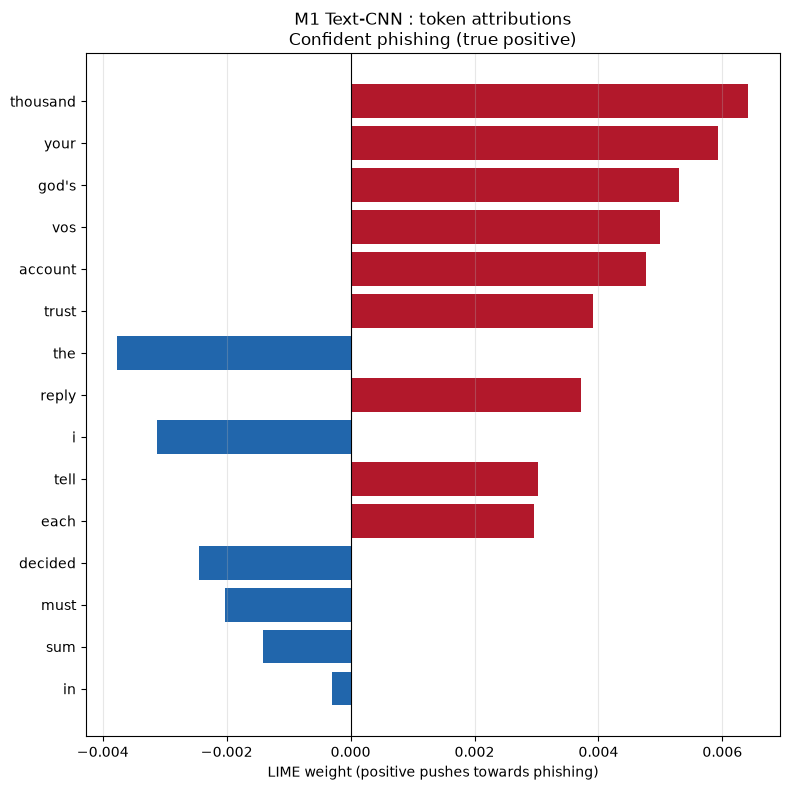

In [14]:
figure_case = cases[0][0]
figure_explanation = explanations[figure_case]["m1"]
figure_tokens = figure_explanation.top[: config.explain.num_features]

fig, ax = plt.subplots(figsize=(8, 0.4 * len(figure_tokens) + 2))
positions = range(len(figure_tokens))
weights = [entry.weight for entry in figure_tokens]
colours = ["#b2182b" if weight > 0 else "#2166ac" for weight in weights]

ax.barh(list(positions), weights, color=colours)
ax.set_yticks(list(positions))
ax.set_yticklabels([entry.token for entry in figure_tokens])
ax.invert_yaxis()
ax.axvline(0.0, color="black", linewidth=0.8)
ax.set_xlabel("LIME weight (positive pushes towards phishing)")
ax.set_title(f"M1 Text-CNN : token attributions\n{figure_case}")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()

figures_dir = Path(config.paths.figures)
figures_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figures_dir / "m1_lime_attributions.png", dpi=config.evaluation.figure_dpi)
plt.show()

## Figure: M0 against M1 on the same email

The two models' weights for the tokens either one considered important,
side by side. Where a bar is present for one model and absent for the
other, that token mattered to one and not the other.

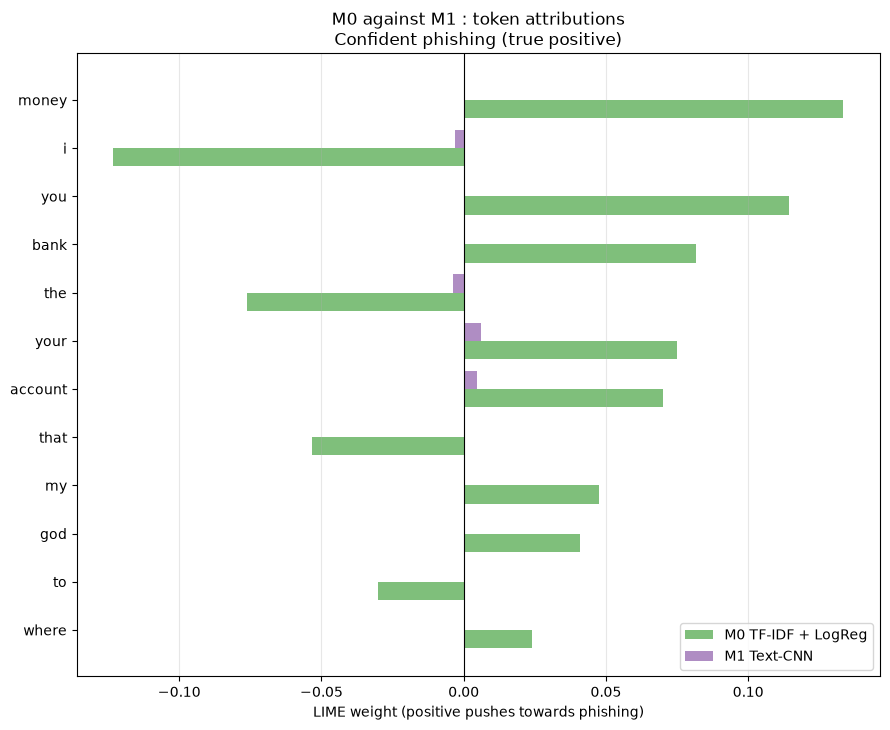

In [15]:
m0_figure = explanations[figure_case]["m0"]
m1_figure = explanations[figure_case]["m1"]

m0_weights = {entry.token: entry.weight for entry in m0_figure.top}
m1_weights = {entry.token: entry.weight for entry in m1_figure.top}
shared_tokens = sorted(
    set(m0_weights) | set(m1_weights),
    key=lambda token: -max(abs(m0_weights.get(token, 0.0)), abs(m1_weights.get(token, 0.0))),
)[:12]

fig, ax = plt.subplots(figsize=(9, 0.45 * len(shared_tokens) + 2))
offsets = range(len(shared_tokens))
height = 0.38
ax.barh(
    [position + height / 2 for position in offsets],
    [m0_weights.get(token, 0.0) for token in shared_tokens],
    height=height,
    label="M0 TF-IDF + LogReg",
    color="#7fbf7b",
)
ax.barh(
    [position - height / 2 for position in offsets],
    [m1_weights.get(token, 0.0) for token in shared_tokens],
    height=height,
    label="M1 Text-CNN",
    color="#af8dc3",
)
ax.set_yticks(list(offsets))
ax.set_yticklabels(shared_tokens)
ax.invert_yaxis()
ax.axvline(0.0, color="black", linewidth=0.8)
ax.set_xlabel("LIME weight (positive pushes towards phishing)")
ax.set_title(f"M0 against M1 : token attributions\n{figure_case}")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / "m0_vs_m1_lime_attributions.png", dpi=config.evaluation.figure_dpi)
plt.show()

## The false positive, read closely

The case `notebooks/README.md` asks this notebook to produce: a legitimate
email the model flagged, with the tokens that drove the mistake. This is
where an explanation earns its place : the verdict alone says the model was
wrong, the explanation says *why*, and whether the reason is a genuine
lure-like phrase in a benign email or a corpus artefact of the kind the
corpus probe and the LOCO evaluation exist
to measure.

In [16]:
false_positive_case = next(
    (name for name in explanations if name.startswith("False positive")), None
)

if false_positive_case is None:
    print("No validation false positive at the selected threshold: nothing to review.")
else:
    bundle = explanations[false_positive_case]
    row = bundle["row"]
    explanation = bundle["m1"]
    print(f"Corpus: {row['corpus']}")
    print(f"True label: {row[label_column]} (legitimate)")
    print(f"M1 P(phishing): {explanation.probability:.4f} at threshold {selected_threshold:.4f}")
    print()
    print("Tokens that pushed this legitimate email towards phishing:")
    for entry in explanation.top:
        if entry.pushes_towards_phishing():
            print(f"  {entry.token!r:>18}  {entry.weight:+.4f}  [{entry.start}:{entry.end}]")
    print()
    print("Tokens that pushed it (correctly) towards legitimate:")
    for entry in explanation.top:
        if not entry.pushes_towards_phishing():
            print(f"  {entry.token!r:>18}  {entry.weight:+.4f}  [{entry.start}:{entry.end}]")
    print()
    print("--- The normalised text the model actually saw (first 600 characters) ---")
    print(explanation.text[:600])

Corpus: Ling
True label: 0 (legitimate)
M1 P(phishing): 1.0000 at threshold 0.5698

Tokens that pushed this legitimate email towards phishing:
             'madam'  +0.1171  [41:46]
          'software'  +0.0884  [7:15]
               'sir'  +0.0728  [35:38]
              'iatl'  +0.0587  [128:132]
              'dear'  +0.0554  [30:34]
               'you'  +0.0453  [55:58]
       'information'  +0.0148  [78:89]
              'send'  +0.0132  [66:70]

Tokens that pushed it (correctly) towards legitimate:
               'for'  -0.0435  [16:19]
         'macintosh'  -0.0385  [20:29]
            'please'  -0.0250  [59:65]
             'about'  -0.0214  [90:95]
             'would'  -0.0109  [49:54]
            'korean'  -0.0109  [0:6]
       'proceedings'  -0.0082  [133:144]

--- The normalised text the model actually saw (first 600 characters) ---
korean software for macintosh dear sir / madam , would you please send me any information about korean software for macintosh , iatl proceedi

## Alignment check on real emails

`tests/critical/test_attribution_alignment.py` proves the alignment
invariants on fixtures. This cell asserts the same invariants on every
real email explained above, so the notebook itself carries the evidence:

1. every offset pair slices the explained text back to its own token,
2. token spans are disjoint and strictly increasing,
3. the reported token sequence is exactly the tokeniser's own output for
   the normalised text.

In [17]:
from phishlens.features.tokenise import tokenise

checked = 0
for name, bundle in explanations.items():
    for model_name in ("m0", "m1"):
        explanation = bundle[model_name]

        assert verify_offsets(explanation), f"Offset mismatch in {model_name} for {name}"

        for previous, current in zip(explanation.tokens, explanation.tokens[1:]):
            assert current.start >= previous.end, f"Overlapping spans in {model_name} for {name}"

        expected = tokenise(normalise_text(bundle["row"]["text"], config))
        assert [entry.token for entry in explanation.tokens] == expected, (
            f"Token sequence mismatch in {model_name} for {name}"
        )
        checked += 1

print(f"Alignment invariants verified on {checked} real explanations.")
print("Every offset slices back to its own token; spans are disjoint and in order.")

Alignment invariants verified on 8 real explanations.
Every offset slices back to its own token; spans are disjoint and in order.


## Cross-check: Integrated Gradients for M1

LIME treats M1 as a black box. Integrated Gradients (Sundararajan et al.,
2017) instead uses the model's own gradients: it walks a straight path from
a **baseline** input to the email and adds up how much each token's
embedding moved the phishing logit along the way. If two methods built on
different principles point at the same tokens, that is better evidence the
tokens really drove the verdict than either method alone.

How it is set up (`src/phishlens/explain/integrated_gradients.py`):

- **Baseline:** the all-`<pad>` sequence. Pad's embedding is fixed at zero,
  so the baseline is "no words at all", and padded positions receive exactly
  zero attribution.
- **Sign:** attributions are to the phishing logit, so a positive score
  pushes towards phishing : the same convention as LIME, with no re-signing.
- **Completeness:** the scores must add up to logit(email) minus
  logit(baseline). The function refuses a result that misses by more than
  5% of that gap, so every row below has passed this check.
- **Alignment:** encoder position *i* is token *i* of the normalised text,
  the same token list `align_to_tokens` walks, so scores land on the same
  character offsets the LIME explanation uses.

Two differences matter when reading the comparison. LIME scores a word
**type** (removing every occurrence at once), while IG scores each
**occurrence**, so IG is summed per word type before the two are compared.
And M1 uses max-over-time pooling, which passes gradient only to the
window that wins each filter : a word repeated in the email can be credited
at one occurrence and score zero at the others.

In [18]:
from phishlens.explain.integrated_gradients import integrated_gradients
from phishlens.explain.method_agreement import method_agreement

print(inspect.getsource(integrated_gradients))

def integrated_gradients(
    text: str, model: nn.Module, vocabulary: Vocabulary, config: Config
) -> IGExplanation:
    """Attribute M1's phishing logit to each token occurrence with IG.

    Attributions are taken at the embedding layer against the all-`<pad>`
    baseline, whose embedding is fixed at zero. Encoder
    position i is token i of the normalised text, which is exactly the list
    `align_to_tokens` walks, so scores are attached by position.

    Inputs: text : raw or normalised email; model : TextCNN with best weights;
    vocabulary : its training vocabulary; config : supplies explain.ig_steps
    and features.max_sequence_length.
    Output: an IGExplanation.

    Raises ValueError if the text has no tokens, if padded positions receive
    attribution, or if completeness fails beyond COMPLETENESS_TOLERANCE.
    """
    normalised = normalise_text(text, config)
    aligned = align_to_tokens(normalised, {})
    if not aligned:
        raise ValueError("Cannot attribute 

D:\S2\ITRI625\C_PhishLens\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [19]:
ig_results = {}
ig_rows = []
for name, bundle in explanations.items():
    ig = integrated_gradients(bundle["row"]["text"], m1_model, vocabulary, config)
    agreement = method_agreement(bundle["m1"], ig)
    ig_results[name] = {"ig": ig, "agreement": agreement}
    gap = ig.logit - ig.baseline_logit
    ig_rows.append(
        {
            "case": name,
            "logit gap": round(gap, 4),
            "attribution sum": round(sum(entry.weight for entry in ig.tokens), 4),
            "completeness error": round(abs(ig.convergence_delta), 6),
            "tokens seen": ig.tokens_seen,
            "LIME/IG jaccard": round(agreement.jaccard, 4),
            "sign agreement": agreement.sign_agreement,
        }
    )
    print(f"{name}")
    print(f"  LIME top tokens: {', '.join(agreement.lime_top)}")
    print(f"  IG top tokens:   {', '.join(agreement.ig_top)}")
    print(f"  Shared: {', '.join(agreement.shared) or 'none'}")
    print()

ig_table = pd.DataFrame(ig_rows)
ig_table

Confident phishing (true positive)
  LIME top tokens: thousand, your, god's, vos, account, trust, the, reply, i, tell, each, decided, must, sum, in
  IG top tokens:   thousand, your, money, guardian, country, dollars, million, united, hundred, you, account, the, bank, so, i
  Shared: thousand, your, account, the, i



Confident legitimate (true negative)
  LIME top tokens: crenshaw, <num>, mark, enron, thanks, cindy, meeting, october, would, back, jennifer, mulholland, burns, am, fri
  IG top tokens:   enron, vince, kaminski, j, beth, re, christie, mulholland, sarah, wharton, hou, cc, burns, lets, patrick
  Shared: enron, mulholland, burns

False positive : legitimate, flagged
  LIME top tokens: madam, software, sir, iatl, dear, you, for, macintosh, please, about, information, send, would, korean, proceedings
  IG top tokens:   madam, sir, dear, you, macintosh, would, about, korean, please, for, me, software, proceedings, any, iatl
  Shared: madam, software, sir, iatl, dear, you, for, macintosh, please, about, would, korean, proceedings



Borderline : nearest the threshold
  LIME top tokens: have, no, secret, words, need, <url>, a
  IG top tokens:   secret, no, words, have, <url>, a, need
  Shared: have, no, secret, words, need, <url>, a



,case,logit gap,attribution sum,completeness error,tokens seen,LIME/IG jaccard,sign agreement
0,Confident phishing (true positive),17.5099,17.5087,0.001163,400,0.2000,1.000000
1,Confident legitimate (true negative),-35.2245,-35.2383,0.013763,212,0.1111,1.000000
2,"False positive : legitimate, flagged",11.7827,11.7835,0.000858,21,0.7647,1.000000
3,Borderline : nearest the threshold,0.2386,0.2351,0.003409,7,1.0000,0.857143


In [20]:
ig_checked = 0
for name, result in ig_results.items():
    ig = result["ig"]
    lime_tokens = explanations[name]["m1"].tokens
    assert all(ig.text[e.start : e.end] == e.token for e in ig.tokens), f"IG offset mismatch for {name}"
    assert [(e.token, e.start, e.end) for e in ig.tokens] == [
        (e.token, e.start, e.end) for e in lime_tokens
    ], f"IG and LIME disagree on token positions for {name}"
    ig_checked += 1

print(f"IG explanations whose offsets slice back to their tokens: {ig_checked} of {len(ig_results)}")
print(f"IG token positions identical to LIME's: {ig_checked == len(ig_results)}")
print(f"Largest completeness error: {ig_table['completeness error'].max():.2e}")
print(f"Mean LIME/IG top-k Jaccard: {ig_table['LIME/IG jaccard'].mean():.4f}")
print(f"Mean sign agreement on shared tokens: {ig_table['sign agreement'].dropna().mean():.4f}")

IG explanations whose offsets slice back to their tokens: 4 of 4
IG token positions identical to LIME's: True
Largest completeness error: 1.38e-02
Mean LIME/IG top-k Jaccard: 0.5190
Mean sign agreement on shared tokens: 0.9643


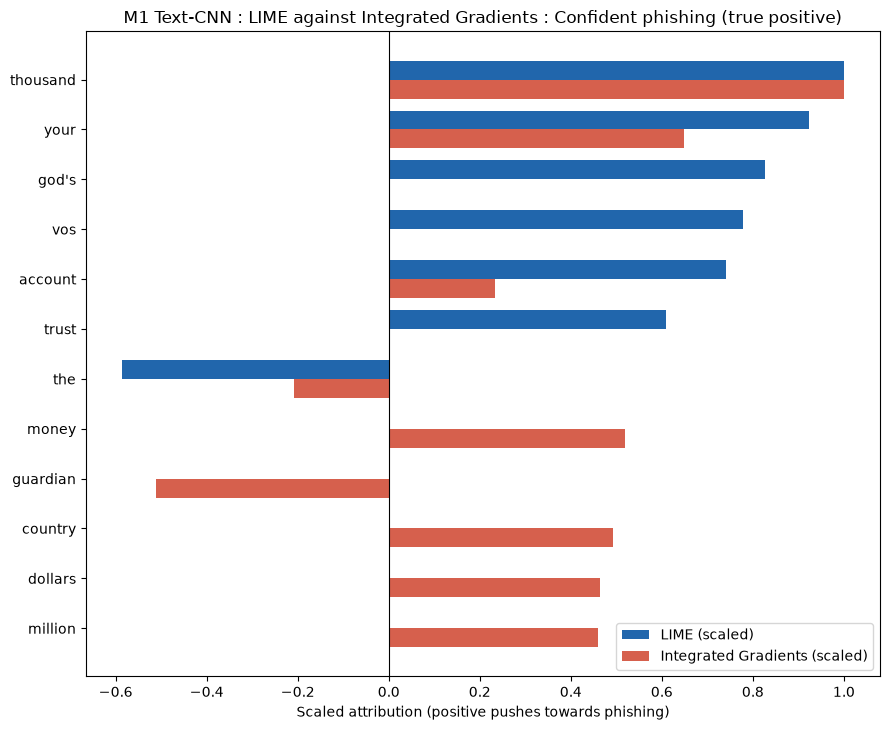

Figure saved to artifacts\figures\xai_lime_vs_ig.png


In [21]:
ig_figure = ig_results[figure_case]
lime_weights = {entry.token: entry.weight for entry in explanations[figure_case]["m1"].top}
ig_type_weights = ig_figure["ig"].type_weights()
# Top 7 from each method, so words only one method ranks highly are shown.
figure_words = list(dict.fromkeys(list(ig_figure["agreement"].lime_top[:7]) + list(ig_figure["agreement"].ig_top[:7])))

# The two methods use different units (LIME: surrogate coefficients; IG:
# logit contributions), so each is scaled by its own largest absolute value.
lime_scale = max(abs(w) for w in lime_weights.values()) or 1.0
ig_scale = max(abs(ig_type_weights.get(t, 0.0)) for t in figure_words) or 1.0

fig, ax = plt.subplots(figsize=(9, 0.45 * len(figure_words) + 2))
rows = range(len(figure_words))
height = 0.38
ax.barh([r - height / 2 for r in rows], [lime_weights.get(t, 0.0) / lime_scale for t in figure_words],
        height=height, label="LIME (scaled)", color="#2166ac")
ax.barh([r + height / 2 for r in rows], [ig_type_weights.get(t, 0.0) / ig_scale for t in figure_words],
        height=height, label="Integrated Gradients (scaled)", color="#d6604d")
ax.set_yticks(list(rows))
ax.set_yticklabels(figure_words)
ax.invert_yaxis()
ax.axvline(0.0, color="black", linewidth=0.8)
ax.set_xlabel("Scaled attribution (positive pushes towards phishing)")
ax.set_title(f"M1 Text-CNN : LIME against Integrated Gradients : {figure_case}")
ax.legend(loc="lower right")
fig.tight_layout()

figure_path = Path(config.paths.figures) / "xai_lime_vs_ig.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=config.evaluation.figure_dpi)
plt.show()
print(f"Figure saved to {figure_path}")

In [22]:
# The strongest IG tokens per case, signed, with each one's share of the
# logit gap (attributions sum to the gap, so shares are comparable).
for name, result in ig_results.items():
    ig = result["ig"]
    gap = ig.logit - ig.baseline_logit
    weights = ig.type_weights()
    print(f"{name} (logit gap {gap:+.2f})")
    for token in sorted(weights, key=lambda t: -abs(weights[t]))[:8]:
        direction = "phishing" if weights[token] > 0 else "legitimate"
        print(f"  {token!r:>14}  {weights[token]:+8.3f}  towards {direction:<10}  {weights[token] / gap:+7.1%} of gap")
    print()


Confident phishing (true positive) (logit gap +17.51)
      'thousand'    +5.021  towards phishing     +28.7% of gap
          'your'    +3.259  towards phishing     +18.6% of gap
         'money'    +2.608  towards phishing     +14.9% of gap
      'guardian'    -2.564  towards legitimate   -14.6% of gap
       'country'    +2.477  towards phishing     +14.1% of gap
       'dollars'    +2.330  towards phishing     +13.3% of gap
       'million'    +2.304  towards phishing     +13.2% of gap
        'united'    +2.018  towards phishing     +11.5% of gap

Confident legitimate (true negative) (logit gap -35.22)
         'enron'   -27.305  towards legitimate   +77.5% of gap
         'vince'    -6.869  towards legitimate   +19.5% of gap
      'kaminski'    -2.845  towards legitimate    +8.1% of gap
             'j'    -2.227  towards legitimate    +6.3% of gap
          'beth'    -1.163  towards legitimate    +3.3% of gap
            're'    +1.144  towards phishing      -3.2% of gap
      '

### Reading the LIME and IG comparison

- **The mechanics hold on real emails.** Every IG offset slices back to its
  own token and sits at exactly the position LIME uses, and every run passed
  the completeness check: the attributions add up to the logit gap, with the
  largest error shown above, well inside the 5% tolerance.
- **Where the email is short, the two methods agree almost completely.** On
  the false positive and the borderline email the top-k sets overlap heavily
  and the shared tokens point the same way. For the false positive this is
  the important result: a gradient-based method, built on different
  principles from LIME, independently finds the salutation (*madam, sir,
  dear*) pushing towards phishing and the topical words (*macintosh,
  korean*) pulling towards legitimate, with the same signs LIME gave. The
  reading of that mistake in section 3.5 of the report, a formal greeting
  outweighing the subject matter, is therefore not an artefact of LIME's
  sampling.
- **On long emails they diverge, and IG reads more plausibly.** The
  confident phishing email (an advance-fee letter, truncated at 400 tokens)
  is exactly the case where LIME was unstable across seeds (Jaccard 0.15 in
  the stability table). There IG pushes towards phishing on the advance-fee
  vocabulary (*thousand, money, country, dollars, million, bank*) where LIME
  surfaced *god's, vos, trust*; IG also finds a word pulling the other way
  (*guardian*). With 1 000 perturbations spread over hundreds of distinct
  words, LIME's surrogate is thin; IG has no sampling step to be thin.
- **IG puts a number on the corpus artefact.** For the confident legitimate
  email, the single token *enron* carries the large majority of the logit
  gap on its own (see the share printed above). The model is confident this
  email is legitimate mostly because it names the Enron archive, which is
  the corpus-recognition effect the probe measures, here
  visible inside one prediction.
- **Where they share a token, they almost always agree on its direction**
  (mean sign agreement above), so the two methods disagree about *which*
  tokens matter most far more often than about *which way* a token pushes.


In [23]:
import json

ig_payload = {
    "commit": run_commit,
    "seed": config.seed,
    "method": "integrated_gradients",
    "baseline": "all <pad> (zero embedding)",
    "ig_steps": config.explain.ig_steps,
    "emails_explained": ig_checked,
    "max_completeness_error": float(ig_table["completeness error"].max()),
    "mean_lime_ig_jaccard": round(float(ig_table["LIME/IG jaccard"].mean()), 4),
    "mean_sign_agreement": round(float(ig_table["sign agreement"].dropna().mean()), 4),
    "per_case": [
        {**row, "agreement": ig_results[row["case"]]["agreement"].as_dict()} for row in ig_rows
    ],
}
ig_metrics_path = Path(config.paths.metrics) / "xai_ig_agreement.json"
ig_metrics_path.write_text(json.dumps(ig_payload, indent=2, sort_keys=True) + "\n", encoding="utf-8")
print(f"LIME/IG agreement metrics written to {ig_metrics_path}")

LIME/IG agreement metrics written to artifacts\metrics\xai_ig_agreement.json


## Summary for the report

The numbers this notebook contributes to report sections 3.3 and 3.4, and
to the XAI bonus.

In [24]:
summary = {
    "commit": run_commit,
    "seed": config.seed,
    "method": config.explain.method,
    "num_features": config.explain.num_features,
    "num_samples": config.explain.num_samples,
    "stability_seeds": list(config.explain.stability_seeds),
    "emails_explained": len(explanations),
    "explanations_computed": checked,
    "m1_selected_threshold": round(float(selected_threshold), 4),
    "mean_seed_jaccard": round(float(stability_table["jaccard"].mean()), 4),
    "min_seed_jaccard": round(float(stability_table["jaccard"].min()), 4),
    "max_probability_spread": float(max_spread),
    "mean_m0_m1_jaccard": round(float(agreement_table["jaccard"].mean()), 4),
}

for key, value in summary.items():
    print(f"{key}: {value}")

commit: 099dd243596fa98094809253892ed7a049b7b04a
seed: 42
method: lime
num_features: 15
num_samples: 1000
stability_seeds: [42, 1337]
emails_explained: 4
explanations_computed: 8
m1_selected_threshold: 0.5698
mean_seed_jaccard: 0.6389
min_seed_jaccard: 0.1538
max_probability_spread: 0.0
mean_m0_m1_jaccard: 0.5705


In [25]:
import json

metrics_dir = Path(config.paths.metrics)
metrics_dir.mkdir(parents=True, exist_ok=True)
explain_metrics_path = metrics_dir / "xai_stability.json"

payload = {
    **summary,
    "per_case_stability": stability_rows,
    "per_case_model_agreement": agreement_rows,
}
explain_metrics_path.write_text(
    json.dumps(payload, indent=2, sort_keys=True) + "\n", encoding="utf-8"
)

print(f"Stability and agreement metrics written to {explain_metrics_path}")

Stability and agreement metrics written to artifacts\metrics\xai_stability.json


## What this notebook establishes

- **Alignment is correct.** Every character offset reported for every real
  email slices the explained text back to exactly its own token, spans are
  disjoint and in reading order, and the token sequence is the tokeniser's
  own output. This is asserted here on real data and proved on adversarial
  fixtures (a repeated token, a token that is a substring of another, the
  `<url>` and `<num>` placeholders) in
  `tests/critical/test_attribution_alignment.py`.
- **The explanation describes the deployed pipeline.** Both models are
  explained through `explain/predict_fn.py`, the same wrapper the
  `/explain` endpoint calls.
- **Explanations are reproducible under a fixed seed, and only partly
  reproducible across seeds.** The probability spread across seeds is
  exactly zero, confirming the predict path is deterministic, so the
  Jaccard overlap above measures LIME's own sampling variability and
  nothing else. That overlap is reported as a stated limitation, not
  smoothed over : it is the honest caveat attached to every highlighted
  token the desktop app will show.
- **A second method agrees where it matters.** Integrated Gradients, which
  uses M1's gradients rather than sampling, lands on the same offsets,
  satisfies completeness on every email, confirms the false-positive
  reading, and shows the corpus artefact directly (*enron* alone carries
  most of the legitimate email's logit gap). It disagrees with LIME mainly
  on long emails, where LIME was already unstable across seeds.
- **An explanation is local.** These weights describe each individual
  prediction, not the model's global behaviour. The global question : is
  the model reading phishing or reading corpus artefacts : is answered by
  the corpus probe and the leave-one-corpus-out evaluation
, not by LIME.